# Bab 1 - Pengenalan Deep Learning: Mengapa Anda Harus Mempelajarinya

**Buku:** *Grokking Deep Learning* (Andrew W. Trask, Manning)

> Bab ini hampir tidak berisi kode di dalam buku; bab ini merupakan pengenalan konseptual. Seperti yang dicatat
> dalam instruksi tugas, untuk materi non-koding fokusnya adalah pada penjelasan konsep secara komprehensif. Saya menambahkan satu
> demonstrasi numpy kecil di akhir untuk membuat gagasan utama menjadi konkret.

## Ringkasan bab
Bab 1 menjelaskan **mengapa** deep learning layak dipelajari dan **apa** yang Anda butuhkan untuk mempelajarinya.

* **Deep learning (DL)** adalah subbidang dari **machine learning (ML)**, yang merupakan subbidang dari **kecerdasan buatan (artificial intelligence / AI)**. DL menggunakan *jaringan saraf tiruan (artificial neural networks)* dengan banyak layer untuk mempelajari pola secara langsung dari data.
* Bidang ini telah berpindah dari laboratorium penelitian ke dalam produk sehari-hari (penerjemahan, pengenalan suara, pencarian gambar, sistem rekomendasi, agen pemutar game), dan permintaan akan orang yang memahaminya sangat tinggi.
* Pendekatan pengajaran buku ini adalah membangun segalanya **dari nol dengan numpy** terlebih dahulu (alih-alih memulai dengan framework seperti PyTorch atau TensorFlow) sehingga Anda memahami apa yang dilakukan framework untuk Anda. Framework baru diperkenalkan di bab selanjutnya dalam buku ini.
* Prasyarat satu-satunya hanyalah dasar-dasar Python dan matematika tingkat SMA; bab ini merekomendasikan penggunaan Jupyter notebook, numpy, dan kesediaan untuk bereksperimen.
* Bab ini merekomendasikan belajar melalui *membaca, mengoding, dan bereksperimen* daripada sekadar membaca pasif, karena intuisi untuk DL berasal dari mengubah angka dan mengamati apa yang terjadi.

## Teori secara mendalam

### AI vs. ML vs. DL
| Istilah | Makna |
|---|---|
| **Kecerdasan Buatan (AI)** | Tujuan luas untuk membuat mesin melakukan tugas-tugas yang biasanya membutuhkan kecerdasan manusia. |
| **Machine Learning (ML)** | Algoritma yang *mempelajari* pemetaan dari data alih-alih diprogram secara eksplisit dengan aturan. |
| **Deep Learning (DL)** | ML yang menggunakan jaringan saraf dengan beberapa layer, yang dapat mempelajari *fitur*-nya sendiri dari input mentah. |

### Mengapa "deep" (dalam)?
"Deep" mengacu pada jumlah **layer** (tahapan komputasi) antara input dan output. Setiap layer mengubah
inputnya menjadi representasi yang sedikit lebih abstrak. Dalam pengenalan gambar, misalnya, layer awal dapat mendeteksi
tepi, layer menengah menggabungkan tepi menjadi bentuk, dan layer akhir mengenali objek. Sebelum deep learning, insinyur harus
merancang fitur-fitur tersebut secara manual ("feature engineering"); DL mempelajarinya secara otomatis.

### Mengapa sekarang?
Tiga faktor penting saling melengkapi: (1) **dataset berukuran besar**, (2) **perangkat keras cepat** (GPU) yang melakukan aritmatika matriks yang dibutuhkan jaringan saraf, dan (3) **algoritma/trik pelatihan yang lebih baik**.
Gagasan dasarnya (neuron, gradient descent, backpropagation) sudah berusia puluhan tahun.

### Jaringan saraf dan otak
Neuron tiruan *diinspirasi secara longgar* oleh neuron biologis: mereka menerima sinyal, menggabungkannya, dan menghasilkan output.
Namun, DL modern lebih tepat dianggap sebagai **pengevaluasi fungsi matematis** yang dibangun dari bagian-bagian sederhana yang dapat disesuaikan
daripada sebagai simulasi otak yang persis. Buku ini menekankan bahwa matematikanya jauh lebih sederhana dari yang ditakutkan orang:
sebagian besar berupa **penjumlahan, perkalian, dan beberapa fungsi sederhana**.

### Gagasan utama: sebuah model adalah fungsi dengan "knob" yang dapat disesuaikan
Sisa buku ini dibangun di atas satu pola sederhana:

1. **Predict (Prediksi):** gunakan knob saat ini (disebut **bobot**) untuk menghitung output dari input.
2. **Compare (Bandingkan):** ukur seberapa salah prediksinya (disebut **error**).
3. **Learn (Belajar):** sesuaikan knob sedikit agar error menjadi lebih kecil.
4. Ulangi.

Semua bab hingga Bab 10 adalah variasi tentang cara melakukan langkah 3 dengan baik dan cara mengatur knob ke dalam jaringan yang lebih besar.

final weight = 0.400  (ideal = 0.4)
final prediction = 0.800  (goal = 0.8)


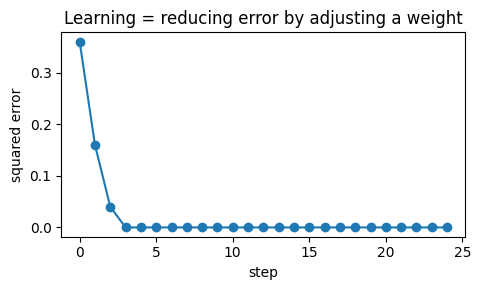

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Model "satu-knob": prediksi = bobot * input. Belajar dengan menggeser knob agar error berkurang.
x, goal = 2.0, 0.8        # satu contoh pelatihan (input dan apa yang ingin kita prediksi)
weight, step = 0.1, 0.1   # knob (bobot), dan seberapa besar pergeseran yang diambil

errors = []
for _ in range(25):
    pred = x * weight
    error = (pred - goal) ** 2
    errors.append(error)
    # coba geser ke atas dan ke bawah, pertahankan mana yang memberikan error lebih kecil (pembelajaran "hot and cold", lihat Bab 4)
    up = (x * (weight + step) - goal) ** 2
    down = (x * (weight - step) - goal) ** 2
    if up < down and up < error:
        weight += step
    elif down < up and down < error:
        weight -= step
    else:
        step /= 2          # buat pergeseran lebih kecil jika sudah dekat

print(f'final weight = {weight:.3f}  (ideal = {goal / x})')
print(f'final prediction = {x * weight:.3f}  (goal = {goal})')

plt.figure(figsize=(5, 3))
plt.plot(errors, marker='o')
plt.xlabel('langkah'); plt.ylabel('squared error'); plt.title('Belajar = mengurangi error dengan menyesuaikan bobot')
plt.tight_layout(); plt.show()

Error berkurang hingga hampir nol dan bobot mengendap di sekitar 0.4, nilai yang membuat `weight * 2.0` sama dengan target 0.8.
Itulah arti inti dari "pembelajaran". Deep learning adalah alur yang sama yang diterapkan pada jutaan bobot.

## Poin-poin kunci
* DL adalah subhimpunan dari ML, yang merupakan subhimpunan dari AI; kekuatannya berasal dari mempelajari fitur secara otomatis di banyak layer.
* Buku ini mengajar dengan membangun segalanya dari nol dalam numpy sehingga tidak ada yang berupa kotak hitam (black box).
* Pembelajaran adalah alur *predict -> compare -> learn*, yang diulangi hingga error menjadi kecil.